# <Paper title>: reproduction and extension

**Student:** <name> · **Paper:** <authors, title, venue, year, link> · **Track:** Docker (ns-3 / Python) or NixNet

**Summary (3-5 sentences):** what the paper claims, what you reproduced, what you changed, and the main result.

> **How to use this template** (delete this box before submitting)
> 1. Keep the sections of the track you use; delete the example sections you do not need.
> 2. Replace the example scenario (`ns3/aanet`, `sim/main.py` or the experiment in `flake.nix`) with your own.
> 3. Every experiment runs through `runner.py`, which caches results in `results/`. Re-running a cell only runs what is missing.
> 4. Before submitting: commit, clone into a fresh folder, follow the README and run this notebook top to bottom (*Kernel → Restart & Run All*).

## 0. Setup
`ENGINE="docker"` runs every job in the pinned Docker images and is required for the results you submit.
`ENGINE="local"` runs the same jobs without Docker and is only for debugging.

In [1]:
import os

os.environ.setdefault("ENGINE", "docker")  # set before importing runner
TRACKS = os.environ.get("TRACKS", "ns3,python,nixnet").split(",")  # delete what you do not use

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import runner
from runner import grid, read_iperf3, read_ping, run_nixnet, run_ns3, run_py, sweep

FIG = Path("figures")
FIG.mkdir(exist_ok=True)


def mean_ci(df, by, col):
    """Mean of `col` over seeds with an approximate 95% confidence interval (1.96 x SEM)."""
    g = df.groupby(by)[col]
    out = g.agg(["mean", "std", "count"])
    out["ci95"] = 1.96 * out["std"] / np.sqrt(out["count"])
    return out.reset_index()


pd.Series(runner.environment_info(), name="value").to_frame()  # report this with your results

,value
engine,docker
python,3.12.8
platform,macOS-27.2-arm64-arm-64bit
git_commit,d059d78
git_dirty,True
nix,None
docker,"Docker version 29.9.3, build 5457199"
ns3_image,sky-ns3:3.42 None
py_image,sky-py:1.1 sha256:5ca73b4a7f9ad019d912c5e53dbb...


## 1. Experiment design
- **Research question:** <what the experiment answers>
- **Parameters swept:** <names, values, why these values>
- **Fixed parameters:** <and where they come from in the paper>
- **Metrics:** <definitions and units>
- **Repetitions:** <number of seeds/runs and why it is enough>

## 2. ns-3 experiment (Docker track)
Example: AANET snapshot (`ns3/aanet/aanet.cc`). Aircraft in a 1000 km x 1000 km area, air-to-air links within `commRange`,
min-hop routing, 10 random UDP flows. Each job is one `(params, seed)` pair; the seed is passed to ns-3 as `--RngRun`.

In [2]:
if "ns3" in TRACKS:
    ns3_configs = grid(numNodes=[50, 100], commRange=[200_000, 300_000, 400_000], simTime=[10])
    ns3_seeds = range(1, 6)
    ns3_df = sweep(run_ns3, ns3_configs, ns3_seeds)  # one row per flow, per job
    display(ns3_df.head())

In [3]:
if "ns3" in TRACKS:
    # aggregate flows per run first, then compute mean and CI over seeds
    per_run = (ns3_df.groupby(["numNodes", "commRange", "seed"])
               .agg(reachable=("reachable", "mean"), delay_ms=("mean_delay_ms", "mean"))
               .reset_index())
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for ax, col, label in [(axes[0], "reachable", "Reachable flows (fraction)"),
                           (axes[1], "delay_ms", "Mean end-to-end delay [ms]")]:
        s = mean_ci(per_run, ["numNodes", "commRange"], col)
        for n, g in s.groupby("numNodes"):
            ax.errorbar(g.commRange / 1e3, g["mean"], yerr=g.ci95, marker="o", capsize=3, label=f"{n} aircraft")
        ax.set_xlabel("Air-to-air range [km]")
        ax.set_ylabel(label)
        ax.grid(alpha=0.3)
    axes[0].legend()
    fig.tight_layout()
    fig.savefig(FIG / "ns3_reachability_delay.pdf", bbox_inches="tight")

## 3. The authors' code

The paper links its code ([43]): [kapeldev/SwarmRaft](https://github.com/kapeldev/SwarmRaft), commit `6e9d47d` (the only commit). We include it **unchanged** as a git submodule in `sim/swarmraft`. The repository has no license, so we reference it instead of copying it. Clone this repository with `git clone --recurse-submodules`, or run `git submodule update --init` in an existing clone.

| File | Lines | Purpose |
|---|---|---|
| `Swarm_Drone_Algorithm_Verification.py` | 249 | class `SwarmVerification`, draws Fig. 1 |
| `Scaling_Swarm_Error.py` | 336 | the same class, plus the Monte Carlo loop and plot for Fig. 2 |
| `main.py` | 92 | runs one or both scripts |

The two copies of `SwarmVerification` differ only in the dictionary they return. The code needs numpy, scipy, matplotlib and tqdm.

**How we run it.** `sim/swarmraft_sim.py` wraps the authors' class with the template's contract (`--params '<json>' --seed <int> --out <csv>`). With default parameters it calls the authors' code unchanged; `tests/test_swarmraft_sim.py` checks that the numbers are identical. Our two optional changes (keep the noisy ranges, change the vote tolerance) are in `sim/swarmraft_variants.py` and are only used in Section 4.

In [4]:
SIM = "swarmraft_sim.py"            # sim/swarmraft_sim.py: wraps the authors' code
AUTHORS = Path("sim/swarmraft")      # the authors' repository (git submodule)
FS = range(1, 9)                     # f = 1..8 as in the paper
DIAG = [{"n": 2 * f + 1, "f": f} for f in FS]  # the paper's cases n = 2f + 1
C_BLUE, C_ORANGE, C_AQUA, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
AUTHORS_SETTING = "authors' code (noise discarded)"

if not (AUTHORS / "Scaling_Swarm_Error.py").exists():
    raise RuntimeError("sim/swarmraft is empty: run `git submodule update --init` first")


def run_sim(configs, seed, **fixed):
    """Run sim/swarmraft_sim.py once per config (results cached in results/py/)."""
    return sweep(run_py, [{**c, **fixed} for c in configs], seeds=[seed], script=SIM)


def setting_label(apply_noise, tol):
    return f"noise on, τ = {tol:g} m" if apply_noise else AUTHORS_SETTING

### 3.1 What one run of the code does

One call of `run_full_verification()` is one static snapshot of the swarm. Line numbers refer to `sim/swarmraft/Scaling_Swarm_Error.py`.

1. **Place the swarm** (l. 43). n drones, uniformly at random in a 100 m cube.
2. **Spoof f drones** (l. 46–53). f random drones report their true position plus a random offset of up to ±30 m per axis (29 m on average). The `spoof_offset` argument is ignored. Honest drones report their exact true position.
3. **Measure ranges** (l. 64–70). For every ordered pair the code draws a noisy distance, but stores the true one (l. 70).
4. **Vote** (l. 89–97). For each drone A and every other drone B, compare the distance between their *reported* positions with the measured range: +1 if they differ by less than τ = 0.01 m, else −1. A is flagged if its sum is negative.
5. **Recover** (l. 99–135). For each flagged drone, solve a nonlinear least-squares problem over the ranges to the unflagged drones (soft-L1 loss, started at the spoofed position, at most 3 rounds). If the solution is more than ε = 3 m from the report, it replaces the report; otherwise the drone is cleared. ε is hard-coded at l. 129 and overrides the "adaptive" value computed at l. 86.
6. **Score** (l. 157–162). Error = mean distance between recovered and true position, **over the spoofed drones only**.

**Where n ≥ 2f + 1 comes from.** A spoofed drone disagrees with all n − 1 others. An honest drone agrees with the n − f − 1 other honest drones and disagrees with the f spoofed ones, so its sum is n − 2f − 1. It is never flagged exactly when n ≥ 2f + 1. This holds only because the ranges are exact: two honest drones always agree.

This is Algorithm 1 of the paper (p. 7) step by step, including its input "distance matrix D measured from true geometry". The differences are between this algorithm and the system the paper describes in Section III; see Section 4.

### 3.2 Reproducing Fig. 1

Fig. 1 shows one snapshot each for (n, f) = (6, 2), (11, 5), (16, 7) with seed 42, projected onto the x–y plane. Each job returns one row per drone. The colours differ from the paper; the positions can be compared with Fig. 1 (p. 6) directly.

,,spoofed,flagged,max_error_m
n,f,,,
6,2,2,2,0.0
11,5,5,5,0.0
16,7,7,7,0.0


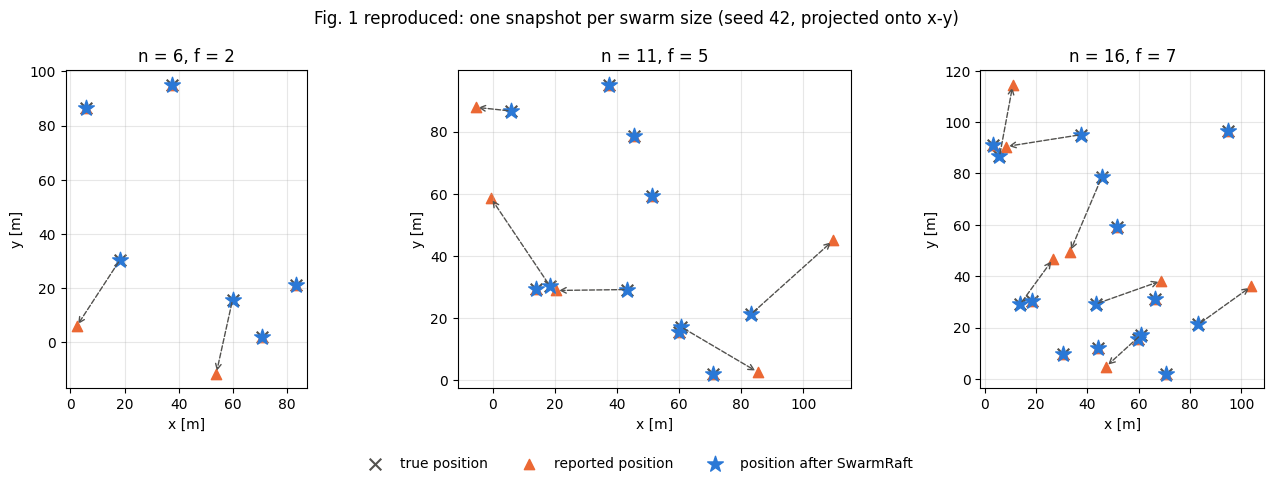

In [5]:
FIG1_CASES = [(6, 2), (11, 5), (16, 7)]
fig1 = run_sim([{"n": n, "f": f, "mode": "scenario"} for n, f in FIG1_CASES], seed=42)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, (n, f) in zip(axes, FIG1_CASES):
    d = fig1[(fig1.n == n) & (fig1.f == f)]
    ax.scatter(d.true_x, d.true_y, marker="x", s=70, c=C_GRAY, label="true position")
    ax.scatter(d.reported_x, d.reported_y, marker="^", s=55, c=C_ORANGE, label="reported position")
    ax.scatter(d.recovered_x, d.recovered_y, marker="*", s=140, c=C_BLUE, zorder=3,
               label="position after SwarmRaft")
    for _, r in d[d.spoofed].iterrows():
        ax.annotate("", xy=(r.reported_x, r.reported_y), xytext=(r.true_x, r.true_y),
                    arrowprops=dict(arrowstyle="->", color=C_GRAY, ls="--", lw=1))
    ax.set(title=f"n = {n}, f = {f}", xlabel="x [m]", ylabel="y [m]", aspect="equal")
    ax.grid(alpha=0.3)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False)
fig.suptitle("Fig. 1 reproduced: one snapshot per swarm size (seed 42, projected onto x-y)")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIG / "fig1_reproduction.pdf", bbox_inches="tight")

spoofed = fig1[fig1.spoofed]
err = np.linalg.norm(spoofed[["recovered_x", "recovered_y", "recovered_z"]].to_numpy()
                     - spoofed[["true_x", "true_y", "true_z"]].to_numpy(), axis=1)
(spoofed.assign(error_m=err).groupby(["n", "f"])
 .agg(spoofed=("drone", "count"), flagged=("flagged", "sum"), max_error_m=("error_m", "max"))
 .round(4))

In all three snapshots every spoofed drone is flagged and put back on its true position (error below 0.1 mm), and the honest drones are untouched. The positions are the same as in the paper's Fig. 1.

### 3.3 Reproducing Fig. 2

Fig. 2 plots, for f = 1…8 and n = 2f + 1, the mean error of the spoofed drones before and after recovery over 10,000 runs. As in the authors' script, every point uses seed 43 and the range-noise setting 0.5 m. One job per point; together they take about 4 minutes on 8 cores the first time and are cached in `results/py/` afterwards. The table compares our numbers with the results the authors committed (`sim/swarmraft/avg_errors.npy`).

In [6]:
fig2 = run_sim(DIAG, seed=43, runs=10_000)  # a few minutes the first time, then cached

stored = pd.DataFrame({"n": np.load(AUTHORS / "ns.npy"),
                       "authors_stored_m": np.load(AUTHORS / "avg_errors.npy")})
summary2 = (fig2.groupby(["n", "f"])
            .agg(spoofed_m=("err_spoofed", "mean"), recovered_m=("err_recovered", "mean"),
                 sd=("err_recovered", "std"), runs=("run", "count"))
            .reset_index().merge(stored, on="n"))
summary2["ci95_m"] = 1.96 * summary2.sd / np.sqrt(summary2.runs)
summary2["ours_minus_stored_m"] = summary2.recovered_m - summary2.authors_stored_m
summary2.drop(columns="sd").round(4)

,n,f,spoofed_m,recovered_m,runs,authors_stored_m,ci95_m,ours_minus_stored_m
0,3,1,28.6822,19.0022,10000,19.0022,0.4045,-0.0
1,5,2,28.8990,5.5026,10000,5.5026,0.2258,-0.0
2,7,3,28.8315,2.2926,10000,2.2926,0.1404,0.0
3,9,4,28.7836,1.2337,10000,1.2337,0.0973,-0.0
4,11,5,28.8502,0.8540,10000,0.8540,0.0723,0.0
5,13,6,28.8013,0.5223,10000,0.5223,0.0544,-0.0
6,15,7,28.8161,0.4085,10000,0.4085,0.0463,0.0
7,17,8,28.7647,0.2873,10000,0.2873,0.0356,0.0


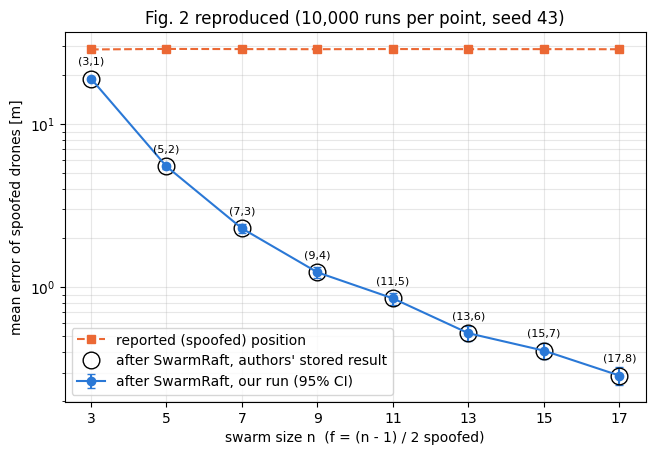

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(summary2.n, summary2.spoofed_m, "s--", c=C_ORANGE, label="reported (spoofed) position")
ax.errorbar(summary2.n, summary2.recovered_m, yerr=summary2.ci95_m, fmt="o-", c=C_BLUE, capsize=3,
            label="after SwarmRaft, our run (95% CI)")
ax.plot(summary2.n, summary2.authors_stored_m, "o", mfc="none", mec="black", ms=12,
        label="after SwarmRaft, authors' stored result")
for n, f, e in summary2[["n", "f", "recovered_m"]].itertuples(index=False):
    ax.annotate(f"({n},{f})", (n, e), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8)
ax.set(yscale="log", xticks=summary2.n, xlabel="swarm size n  (f = (n - 1) / 2 spoofed)",
       ylabel="mean error of spoofed drones [m]", title="Fig. 2 reproduced (10,000 runs per point, seed 43)")
ax.grid(alpha=0.3, which="both")
ax.legend()
fig.savefig(FIG / "fig2_reproduction.pdf", bbox_inches="tight")

**Result.** Our run matches the authors' stored numbers to within 2 × 10⁻⁷ m at every point, in a different environment (Python 3.11, numpy 2.3.5, scipy 1.16.3 in Docker). The paper's "from 19 m to 0.28 m" are the first and last of these numbers.

**Why the curve falls.** At n = 2f + 1 there are f + 1 honest drones to multilaterate from. At n = 3 there are two: two spheres meet in a circle, so the position is not determined and the error stays at 19 m, two thirds of the spoof. At n = 5, three anchors leave two mirror-image solutions. From four anchors on (n ≥ 7) the position is determined, and the remaining error comes from runs in which the recovery fails (Section 4.4). The curve shows how many anchors there are, not how well the scheme copes with noise, because there is none.

## 4. Paper vs. code

The code reproduces the figures exactly, but it simulates much less than the paper describes.

| # | Paper | Code | Consequence |
|---|---|---|---|
| 1 | Raft elects a leader each time step; the leader collects reports, decides and replicates the result to all drones over WiFi (III-A, IV, abstract) | No Raft, no messages, no network. One function reads all positions and ranges directly | Consensus, latency, message cost and leader crashes are not tested |
| 2 | Time steps k, GNSS noise, INS drift, fallback to INS, recovery "based on its last known state and trajectory" after GNSS **loss** (abstract, III-B, III-C, III-F) | One static snapshot. Honest drones report their exact position. No INS, no GNSS loss, only spoofing | The scenario in the abstract (GNSS-denied) is not simulated |
| 3 | Ranges are noisy: d = ‖x_i − x_j‖ + η, η ~ N(0, σ_d²) (III-C) | Noise is drawn, the true distance is stored (l. 70) | The noise setting has no effect (4.1) |
| 4 | Detection compares a residual with a calibrated threshold T = μ_e + 3σ_e, false alarms < 1 % (III-E) | Pairwise vote with τ = 1 cm, then a fixed ε = 3 m (l. 95, 129) | Works only without noise (4.2) |
| 5 | Recovery starts at the centroid of the good neighbours; "median-based" recovery (III-F, III-G) | Starts at the spoofed position (l. 109; the centroid line is commented out); no median | Not tested by us |
| 6 | Three attacks: GNSS spoofing, range tampering, collusion (III-B); "spoofed drones report displaced positions and manipulated ranges" (V-B) | GNSS spoofing only, a random offset of up to ±30 m per axis; ranges are never manipulated | Two of three attacks are not tested |
| 7 | Monte Carlo over every n ∈ {3, …, 17} and f ∈ {1, …, 8} (V-B) | Only n = 2f + 1 | 4.3 |
| 8 | Fig. 2 "compares error distributions": medians, interquartile ranges, outliers (V-B) | Fig. 2 shows means only | 4.4 |
| 9 | Mean absolute error of the recovered positions (V-B) | Averaged over the spoofed drones only; honest drones moved by mistake do not count | We count them (4.2) |
| 10 | "Urban and natural terrains", "real-world scenarios" (I) | Random points in a 100 m cube, no terrain or radio model | Not testable with this code |

The first two rows are the largest gap: the paper's title and first contribution are the Raft adaptation, and none of it is in the code. Rows 3, 4, 7, 8 and 9 can be tested with small changes, which we do below.

### 4.1 The noise setting has no effect

If the range noise were used, changing it would change the results. We run the authors' code with noise 0 and 0.5 m (same seed, 1000 runs per swarm size) and compare every run.

In [8]:
noise_check = run_sim([{**c, "noise": s} for c in DIAG for s in (0.0, 0.5)], seed=43, runs=1000)
cols = ["err_recovered", "err_spoofed", "honest_moved", "spoofed_missed"]
off, on = (noise_check[noise_check.noise == s].reset_index(drop=True)[cols] for s in (0.0, 0.5))
print(f"{len(off)} runs per noise setting (8 swarm sizes x 1000); identical results: {off.equals(on)}")

8000 runs per noise setting (8 swarm sizes x 1000); identical results: True


### 4.2 Turning the noise on

`sim/swarmraft_variants.py` keeps the noisy distance that the code already computes (one line differs; the random draws stay the same). We then vary the vote tolerance τ. With σ_d = 0.5 m, an honest pair's range differs from its reported distance by more than 1 cm almost always, so τ = 1 cm marks nearly every pair as inconsistent. τ = 2 m is 4σ_d, close in spirit to the paper's T = μ + 3σ rule. Besides the paper's metric we count the honest drones that are wrongly flagged and moved.

In [9]:
TOLS = [0.01, 1.0, 2.0, 3.0]  # vote tolerance tau [m]; 0.01 is the authors' value
noisy = run_sim([{**c, "apply_noise": True, "tol": t} for c in DIAG for t in TOLS], seed=43, runs=1000)
authors = noise_check[noise_check.noise == 0.5].assign(apply_noise=False, tol=0.01)
stress = pd.concat([authors, noisy], ignore_index=True)
stress["setting"] = [setting_label(a, t) for a, t in zip(stress.apply_noise, stress.tol)]
summary4 = (stress.groupby(["setting", "n"])
            .agg(recovered_m=("err_recovered", "mean"), honest_moved=("honest_moved", "mean"),
                 spoofed_missed=("spoofed_missed", "mean"))
            .reset_index())
order = [AUTHORS_SETTING] + [setting_label(True, t) for t in TOLS]
print("Mean error of the spoofed drones after SwarmRaft [m]")
display(summary4.pivot(index="n", columns="setting", values="recovered_m")[order].round(2))
print("Honest drones wrongly flagged and moved, per run")
display(summary4.pivot(index="n", columns="setting", values="honest_moved")[order].round(2))

Mean error of the spoofed drones after SwarmRaft [m]


setting,authors' code (noise discarded),"noise on, τ = 0.01 m","noise on, τ = 1 m","noise on, τ = 2 m","noise on, τ = 3 m"
n,,,,,
3,18.73,18.72,19.29,19.95,20.60
5,5.53,19.07,10.73,8.59,9.53
7,1.87,14.51,4.87,3.44,4.02
9,1.25,11.21,3.29,2.37,2.65
11,1.00,9.52,2.42,1.92,2.04
13,0.52,7.89,1.66,1.27,1.36
15,0.35,7.32,1.24,0.99,1.02
17,0.37,6.38,1.12,0.94,0.97


Honest drones wrongly flagged and moved, per run


setting,authors' code (noise discarded),"noise on, τ = 0.01 m","noise on, τ = 1 m","noise on, τ = 2 m","noise on, τ = 3 m"
n,,,,,
3,0.0,1.82,0.08,0.0,0.0
5,0.0,2.94,0.26,0.0,0.0
7,0.0,3.84,0.21,0.0,0.0
9,0.0,4.69,0.16,0.0,0.0
11,0.0,5.46,0.10,0.0,0.0
13,0.0,6.11,0.06,0.0,0.0
15,0.0,6.78,0.04,0.0,0.0
17,0.0,7.22,0.02,0.0,0.0


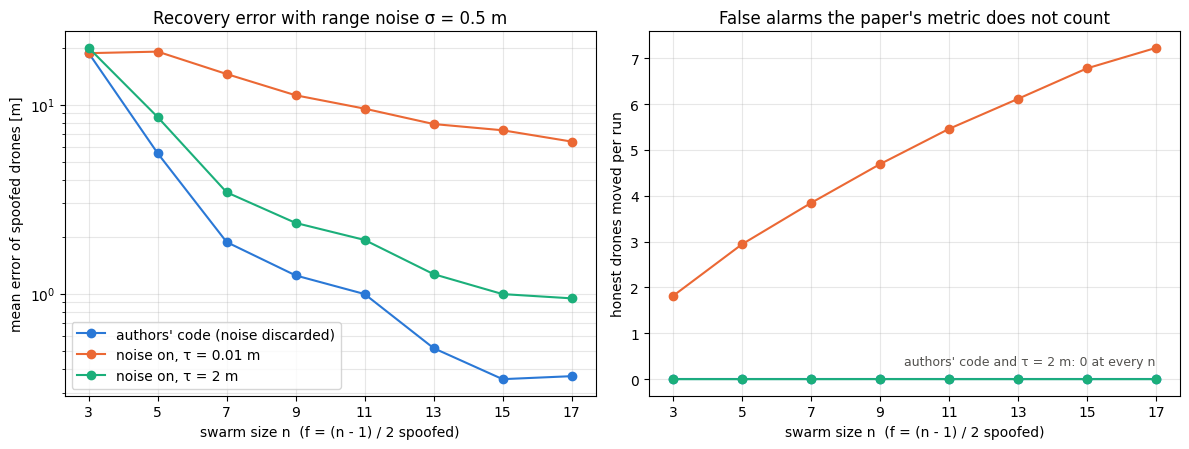

In [10]:
shown = {AUTHORS_SETTING: C_BLUE, setting_label(True, 0.01): C_ORANGE, setting_label(True, 2.0): C_AQUA}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for setting, color in shown.items():
    s = summary4[summary4.setting == setting]
    axes[0].plot(s.n, s.recovered_m, "o-", c=color, label=setting)
    axes[1].plot(s.n, s.honest_moved, "o-", c=color, label=setting)
axes[0].set(yscale="log", ylabel="mean error of spoofed drones [m]",
            title="Recovery error with range noise σ = 0.5 m")
axes[1].set(ylabel="honest drones moved per run", title="False alarms the paper's metric does not count")
for ax in axes:
    ax.set(xlabel="swarm size n  (f = (n - 1) / 2 spoofed)", xticks=summary2.n)
    ax.grid(alpha=0.3, which="both")
axes[0].legend()
axes[1].annotate("authors' code and τ = 2 m: 0 at every n", xy=(17, 0), xytext=(0, 10),
                 textcoords="offset points", ha="right", fontsize=9, color=C_GRAY)
fig.tight_layout()
fig.savefig(FIG / "noise_stress_test.pdf", bbox_inches="tight")

**Result** (1000 runs per point: the first 1000 of the 10,000 runs in Section 3.3, so the authors' column differs slightly from Fig. 2).

- **Authors' tolerance, τ = 1 cm:** almost every honest pair fails the vote. At n = 17, 7.2 of the 9 honest drones are flagged and moved per run, and recovery then uses spoofed drones as anchors. The error of the spoofed drones rises from 0.37 m to 6.4 m. The moved honest drones do not appear in the paper's metric at all.
- **τ = 2 m:** no honest drone is moved, and the error at n = 17 is 0.94 m, about 2.5 times the noise-free value.
- **τ = 1 m** still moves some honest drones, and **τ = 3 m** is slightly worse than 2 m again.

So the scheme can work with noise, but only with a tolerance that the code does not set and the paper does not state, and with errors well above the published curve.

### 4.3 Beyond n = 2f + 1

The paper says it ran every combination of n and f, but the code only runs n = 2f + 1, the hardest case. A fixed swarm of n = 17 with f = 1…8 spoofed drones shows the rest of the picture.

In [11]:
FIXED = [{"n": 17, "f": f} for f in FS]
fixed = pd.concat([run_sim(FIXED, seed=43, runs=1000).assign(setting=AUTHORS_SETTING),
                   run_sim(FIXED, seed=43, runs=1000, apply_noise=True, tol=2.0)
                   .assign(setting=setting_label(True, 2.0))], ignore_index=True)
summary5 = (fixed.groupby(["setting", "f"])
            .agg(recovered_m=("err_recovered", "mean"), honest_moved=("honest_moved", "mean"),
                 spoofed_missed=("spoofed_missed", "mean"))
            .reset_index())
summary5.pivot(index="f", columns="setting", values=["recovered_m", "honest_moved", "spoofed_missed"]).round(3)

recovered_m                    \
setting authors' code (noise discarded) noise on, τ = 2 m   
f                                                           
1                                 0.000             0.462   
2                                 0.059             0.496   
3                                 0.154             0.636   
4                                 0.075             0.547   
5                                 0.086             0.599   
6                                 0.133             0.682   
7                                 0.268             0.841   
8                                 0.366             0.945   

                           honest_moved                    \
setting authors' code (noise discarded) noise on, τ = 2 m   
f                                                           
1                                   0.0               0.0   
2                                   0.0               0.0   
3                                   0.0               0.0   
4                                   0.0               0.0   
5                                   0.0               0.0   
6                                   0.0               0.0   
7                                   0.0               0.0   
8                                   0.0               0.0   

                         spoofed_missed                    
setting authors' code (noise discarded) noise on, τ = 2 m  
f                                                          
1                                 0.000             0.007  
2                                 0.001             0.005  
3                                 0.001             0.003  
4                                 0.002             0.006  
5                                 0.005             0.013  
6                                 0.001             0.007  
7                                 0.003             0.010  
8                                 0.005             0.010

**Result.** With fewer spoofed drones the error is smaller, as expected. At n = 17 the authors' code recovers a single spoofed drone exactly, and eight with 0.37 m error; the small bumps in between come from rare failed runs (Section 4.4). With the noise on (τ = 2 m) the error is 0.46–0.95 m and no honest drone is moved. Even one spoofed drone among 16 honest ones is located only to about 0.5 m: a floor set by the range noise, which the paper never shows.

### 4.4 What the mean hides

The paper describes medians, interquartile ranges and outliers for Fig. 2, but the figure shows only means. From the 10,000 runs per point of Section 3.3:

In [12]:
by_n = fig2.groupby("n").err_recovered
dist = pd.DataFrame({"mean_m": by_n.mean(), "median_m": by_n.median(),
                     "p90_m": by_n.quantile(0.9), "p99_m": by_n.quantile(0.99), "max_m": by_n.max(),
                     "runs_above_1m_pct": 100 * by_n.apply(lambda e: (e > 1).mean())})
dist.round(3)

,mean_m,median_m,p90_m,p99_m,max_m,runs_above_1m_pct
n,,,,,,
3,19.002,14.145,34.926,115.740,178.057,96.33
5,5.503,0.000,19.330,54.159,108.475,33.10
7,2.293,0.000,8.704,35.183,96.238,14.20
9,1.234,0.000,0.000,26.429,65.986,8.41
11,0.854,0.000,0.000,20.362,45.497,6.54
13,0.522,0.000,0.000,16.538,40.172,4.27
15,0.408,0.000,0.000,14.216,39.874,3.55
17,0.287,0.000,0.000,11.591,29.402,2.81


**Result.** From n = 5 on, the median error is zero: in most runs every spoofed drone is recovered exactly. The mean comes from a few runs that fail badly. At n = 17, 2.8 % of runs have an error above 1 m, and the worst has 29 m. So "0.28 m" does not mean that SwarmRaft locates a drone to 28 cm. It means it is exact in about 97 % of runs and off by metres in the rest. We have not yet checked why these runs fail; the solver's start point (row 5 of the table) is one candidate.

### 4.5 Summary

- **Reproduction:** the authors' code reproduces Fig. 1 and Fig. 2 exactly (Fig. 2 to within 2 × 10⁻⁷ m), run through the template's Docker environment.
- **What the figures show:** majority voting plus multilateration on one noise-free snapshot, in the worst case n = 2f + 1. They do not involve Raft, a network, time, INS, GNSS loss, or the other two attacks.
- **Noise:** with the authors' own range noise switched on, their tolerance breaks the scheme (6.4 m instead of 0.37 m at n = 17, 7 of 9 honest drones moved). A 2 m tolerance repairs it at about 2.5 times the error.
- **Statistics:** the means in Fig. 2 come from rare large failures; the median error is zero from n = 5 on.

**Still untested:** the Raft layer (leader election, replication, latency, leader crash), the calibrated threshold T = μ_e + 3σ_e, range tampering and collusion, INS and GNSS loss, and every (n, f) pair with the noise on.

## 5. NixNet experiment (NixNet track)
Example: ground station → aircraft relay → ground station (`flake.nix`). Each air link adds a one-way delay `d` (and optional loss),
so the expected RTT is about 4·d. Experiments are named `relay-d<delay>-l<loss>`; each run is stored in `results/nixnet/<name>/<run>/`.
Start Jupyter with `nix develop -c jupyter lab` so that `nix` is available.

In [13]:
if "nixnet" in TRACKS:
    rows = []
    for exp in [f"relay-d{d}-l{l}" for d in (1, 5, 20) for l in (0, 1)]:
        for run_dir in run_nixnet(exp, runs="1-3"):
            client = run_dir / "gs-west"
            rows.append({"experiment": exp, "run": run_dir.name,
                         **read_ping(client / "ping.txt"), **read_iperf3(client / "iperf3.json")})
    nix_df = pd.DataFrame(rows)
    nix_df[["delay_ms", "loss_pct_cfg"]] = nix_df.experiment.str.extract(r"d(\d+)-l(\d+)").astype(int)
    display(nix_df.head())

In [14]:
if "nixnet" in TRACKS:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for loss, g in nix_df.groupby("loss_pct_cfg"):
        s = mean_ci(g, "delay_ms", "rtt_avg_ms")
        axes[0].errorbar(s.delay_ms, s["mean"], yerr=s.ci95, marker="o", capsize=3, label=f"loss {loss}%")
        s = mean_ci(g, "delay_ms", "throughput_mbps")
        axes[1].errorbar(s.delay_ms, s["mean"], yerr=s.ci95, marker="o", capsize=3, label=f"loss {loss}%")
    d = np.array(sorted(nix_df.delay_ms.unique()))
    axes[0].plot(d, 4 * d, "k--", lw=1, label="expected 4·d")
    axes[0].set_ylabel("RTT [ms]")
    axes[1].set_ylabel("TCP throughput [Mbit/s]")
    for ax in axes:
        ax.set_xlabel("One-way delay per air link [ms]")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.tight_layout()
    fig.savefig(FIG / "nixnet_rtt_throughput.pdf", bbox_inches="tight")

## 6. Results and discussion
- **Reproduction:** which results of the paper you reproduced, and how closely (numbers, figures side by side).
- **Differences:** where your results differ and why (model simplifications, parameters, randomness).
- **Extension:** what you changed or added, and what you learned from it.
- **Limitations:** what your experiment cannot show.

## 7. Reproducibility
- **Environment:** the table printed in section 0 (engine, image IDs or Nix version, git commit).
- **How to reproduce:** see `README.md`. Results are cached in `results/` with a `.json` file per job describing how it was produced.
- **Checklist before submitting:**
  - [ ] all results produced with `ENGINE="docker"` (Docker track) or via `nix develop` (NixNet track)
  - [ ] `flake.lock` / pinned `requirements*.txt` committed
  - [ ] fresh clone + README + *Restart & Run All* works
  - [ ] git working tree clean (`git_dirty` is `False` above)